In [3]:
import sys
import os
import matplotlib.pyplot as plt
import numpy as np
sys.path.append('../../')
from utils_plots import apply_plot_style, get_layers, load_ii_curves, linestyle_for_language
eps = 1E-7
colors, markers, _linestyles = apply_plot_style()
plot_id = 0
sys.path.append(os.path.expanduser('~/syn-sem'))
from modelpaths import get_model_depths
depths = get_model_depths()


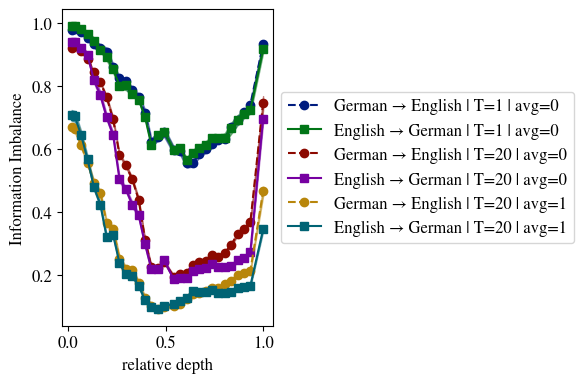

In [7]:
import numpy as np
import matplotlib.pyplot as plt

# -----------------------
# Config
# -----------------------
model = "deepseek"
MODEL_PRETTY = {"deepseek": "DeepSeek-V3", "llama": "L3"}
_model = MODEL_PRETTY.get(model, model)

mask = 2
language_pairs = [
    # ("english", "spanish"),
    ("german", "english"),
    # ("english", "italian"),
]

n_files = 500
batch_size = 10
Ns = batch_size * n_files
batch_shuffle = 0

min_token_length = 40
avg_tokens_list = [0, 1]

k_II = 10
Nbits = 0
seeds_II = list(range(5))

n_tokens_list = [1, 20]
aux_A = "source"
aux_B = "target"

# -----------------------
# Plot
# -----------------------
fig, ax = plt.subplots(1, 1, figsize=(6, 4))

layers = get_layers(model, depths)
x = layers / depths[model]

seen_labels = set()

# Precompute "condition ids" so each (avg_tokens, n_tokens) gets its own color slot
valid_conditions = [
    (avg_tokens, n_tokens)
    for avg_tokens in avg_tokens_list
    for n_tokens in n_tokens_list
    if not (n_tokens == 1 and avg_tokens == 1)
]
cond_to_id = {cond: i for i, cond in enumerate(valid_conditions)}

for avg_tokens in avg_tokens_list:
    for n_tokens in n_tokens_list:
        if n_tokens == 1 and avg_tokens == 1:
            continue

        cond_id = cond_to_id[(avg_tokens, n_tokens)]

        for language_pair_id, (languageA, languageB) in enumerate(language_pairs):

            mean_ii, std_ii = load_ii_curves(
                base="../results/santiago/",
                batch_shuffle=batch_shuffle,
                model=model,
                aux_A=aux_A,
                aux_B=aux_B,
                n_files=n_files,
                min_token_length=min_token_length,
                languageA=languageA,
                languageB=languageB,
                mask=mask,
                k=k_II,
                Nbits=Nbits,
                seeds=seeds_II,
                n_tokens=n_tokens,
                avg_tokens=avg_tokens,
            )

            ls_A = linestyle_for_language(languageA, _linestyles)
            ls_B = linestyle_for_language(languageB, _linestyles)

            # One distinct color per curve:
            # - keep language_pair_id separation
            # - also separate different (avg_tokens, n_tokens) via an offset
            color_idx_AB = (language_pair_id + 2 * cond_id + 0) % len(colors)
            color_idx_BA = (language_pair_id + 2 * cond_id + 1) % len(colors)
            color_AB = colors[color_idx_AB]
            color_BA = colors[color_idx_BA]

            # Markers encode direction:
            marker_AB = "o"  # A -> B
            marker_BA = "s"  # B -> A

            label_AB = f"{languageA.capitalize()} → {languageB.capitalize()} | T={n_tokens} | avg={avg_tokens}"
            label_BA = f"{languageB.capitalize()} → {languageA.capitalize()} | T={n_tokens} | avg={avg_tokens}"

            # A -> B (AB): circles
            use_label = label_AB if label_AB not in seen_labels else None
            ax.plot(
                x,
                mean_ii[0],
                label=use_label,
                linestyle=ls_A,
                color=color_AB,
                marker=marker_AB,
            )
            if use_label:
                seen_labels.add(label_AB)

            ax.fill_between(
                x,
                mean_ii[0] - std_ii[0],
                mean_ii[0] + std_ii[0],
                alpha=0.5,
                color=color_AB,
            )

            # B -> A (BA): squares
            use_label = label_BA if label_BA not in seen_labels else None
            ax.plot(
                x,
                mean_ii[1],
                label=use_label,
                linestyle=ls_B,
                color=color_BA,
                marker=marker_BA,
            )
            if use_label:
                seen_labels.add(label_BA)

            ax.fill_between(
                x,
                mean_ii[1] - std_ii[1],
                mean_ii[1] + std_ii[1],
                alpha=0.5,
                color=color_BA,
            )

ax.set_xlabel("relative depth")
ax.set_ylabel("Information Imbalance")

# Legend outside
box = ax.get_position()
ax.set_position([box.x0, box.y0, box.width * 0.8, box.height])
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5))
fig.savefig(fname=f'../results/figs/fig1_{languageB}.pdf', bbox_inches='tight')
plt.show()
